# 10_base_learner_comparison.ipynb — เปรียบเทียบโมเดลก่อนเลือก Base Learner สำหรับ Stacking

**วัตถุประสงค์**: ก่อนหน้านี้ pipeline สุดท้าย (`07_final_calibrated_pipeline.ipynb`) เลือกใช้ **Random Forest + XGBoost** เป็น base learner และ **Logistic Regression** เป็น meta-learner โดยตรง โน้ตบุ๊กนี้ทำการทดลองย้อนกลับ: เทรน**โมเดลเดี่ยวหลายตระกูล**บนข้อมูลชุดเดียวกัน (cleaning + feature engineering + `GroupShuffleSplit` เหมือนเดิมทุกขั้นตอน) แล้วเปรียบเทียบผลลัพธ์ เพื่อ**ตอบคำถามว่าทำไมถึงเลือก RF+XGBoost** แทนที่จะเลือกโมเดลอื่น

**โมเดลที่นำมาเปรียบเทียบ** (7 ตัว, ครอบคลุม 4 ตระกูลอัลกอริทึม):

| ตระกูล | โมเดล | เหตุผลที่เลือกมาเทียบ |
|---|---|---|
| Linear | Logistic Regression | baseline เชิงเส้น ตีความง่าย ใช้เป็น meta-learner อยู่แล้ว |
| Instance-based | K-Nearest Neighbors | baseline แบบไม่มีสมมติฐานเชิงพารามิเตอร์ |
| Probabilistic | Gaussian Naive Bayes | baseline แบบ probabilistic เร็วมาก |
| Tree (single) | Decision Tree | baseline ต้นไม้เดี่ยว เทียบกับ ensemble ของต้นไม้ |
| Tree (bagging) | Random Forest | ตัวเลือกที่ใช้จริงใน pipeline สุดท้าย |
| Tree (boosting) | AdaBoost | เคยทดสอบใน `04_model_training.ipynb` มาก่อน — เอามาเทียบซ้ำในชุด feature ล่าสุด |
| Tree (boosting) | HistGradientBoosting | ตัวแทน gradient boosting ของ scikit-learn (จะรันคู่กับ XGBoost ถ้ามี package) |
| Tree (boosting) | XGBoost *(ถ้าติดตั้งไว้)* | ตัวเลือกที่ใช้จริงใน pipeline สุดท้าย |

**โมเดลที่ตัดออกจากการเปรียบเทียบ พร้อมเหตุผล** (ตามแนวทาง "rejected methods with rationale" ที่ใช้ในโปรเจกต์นี้มาตลอด):
- **SVM (RBF kernel)**: training complexity ประมาณ O(n²)–O(n³) กับข้อมูล ~79,567 แถวใน training set ทำให้ใช้เวลานานเกินจะคุ้มกับ marginal gain ที่คาดหวัง (linear SVM ให้ผลใกล้เคียง Logistic Regression อยู่แล้วเพราะ feature ส่วนใหญ่ผ่าน label encoding ไม่ใช่ one-hot ทำให้ margin-based method ไม่ได้เปรียบชัดเจน)
- **Neural network / MLP**: จากการตัดสินใจก่อนหน้านี้เรื่อง LSTM ว่าไม่เหมาะกับข้อมูลที่ ~76.5% ของผู้ป่วยมี encounter เดียว จึงไม่มีโครงสร้าง sequence ให้ neural network ใช้ประโยชน์ได้เหนือกว่า tree-based model บนข้อมูล tabular ขนาดนี้

**หมายเหตุเรื่อง imbalance**: ใช้ `class_weight="balanced"` (หรือ `scale_pos_weight` สำหรับ XGBoost) ตรงๆ ไม่ resample เพราะ Experiment A ใน `06_new_experiments.ipynb` สรุปแล้วว่าไม่มีเทคนิค resampling ไหนเอาชนะ class_weight ได้อย่างมีนัยสำคัญ

## 1. Imports

In [ ]:
import warnings
warnings.filterwarnings("ignore")
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, HistGradientBoostingClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    roc_auc_score, average_precision_score, brier_score_loss, fbeta_score
)

try:
    from xgboost import XGBClassifier
    HAS_XGB = True
except ImportError:
    HAS_XGB = False
print(f"XGBoost available in this environment: {HAS_XGB}")

RANDOM_STATE = 42


XGBoost available in this environment: False


## 2. Load & Clean Data (เหมือนเดิมทุกขั้นตอน จาก 07_final_calibrated_pipeline.ipynb)

In [ ]:
RAW_PATH = "../data/diabetic_data.csv"  # แก้ path ตามที่เก็บไฟล์จริง

df = pd.read_csv(RAW_PATH, keep_default_na=False, na_values=["?"])
print(f"Raw shape: {df.shape}")

df = df[df["gender"] != "Unknown/Invalid"]

death_hospice_codes = [11, 13, 14, 19, 20, 21]
df = df[~df["discharge_disposition_id"].isin(death_hospice_codes)]

df = df.sort_values(["patient_nbr", "encounter_id"])
df = df.reset_index(drop=True)
print(f"Shape after cleaning: {df.shape}")

df["readmitted"] = df["readmitted"].apply(lambda x: 1 if x == "<30" else 0)
print(df["readmitted"].value_counts(normalize=True))


Raw shape: (101766, 50)
Shape after cleaning: (99340, 50)
readmitted
0    0.886108
1    0.113892
Name: proportion, dtype: float64


## 3. Feature Engineering (เหมือน 05_improved_pipeline4.ipynb / 07 — ไม่ใส่ LACE score ถาวร)

In [ ]:
med_cols = [
    "metformin", "repaglinide", "nateglinide", "chlorpropamide", "glimepiride",
    "acetohexamide", "glipizide", "glyburide", "tolbutamide", "pioglitazone",
    "rosiglitazone", "acarbose", "miglitol", "troglitazone", "tolazamide",
    "examide", "citoglipton", "insulin", "glyburide-metformin", "glipizide-metformin",
    "glimepiride-pioglitazone", "metformin-rosiglitazone", "metformin-pioglitazone",
]
med_cols = [c for c in med_cols if c in df.columns]

df["medication_change_count"] = (df[med_cols] == "Up").sum(axis=1) + (df[med_cols] == "Down").sum(axis=1)
df["num_meds_active"] = (df[med_cols] != "No").sum(axis=1)
df["tested_glucose"] = (df["max_glu_serum"] != "None").astype(int)
df["tested_A1C"] = (df["A1Cresult"] != "None").astype(int)

df["visit_number"] = df.groupby("patient_nbr").cumcount() + 1
df["change_flag"] = (df["change"] == "Ch").astype(int)
df["prior_change_count"] = df.groupby("patient_nbr")["change_flag"].cumsum() - df["change_flag"]
df = df.drop(columns=["change_flag"])

df["total_prior_visits"] = df["number_outpatient"] + df["number_emergency"] + df["number_inpatient"]
df["had_prior_inpatient"] = (df["number_inpatient"] > 0).astype(int)


In [ ]:
def map_diagnosis(code):
    if pd.isna(code):
        return "Missing"
    code = str(code)
    if code.startswith("V") or code.startswith("E"):
        return "Other"
    try:
        val = float(code)
    except ValueError:
        return "Other"
    if 390 <= val <= 459 or val == 785:
        return "Circulatory"
    elif 460 <= val <= 519 or val == 786:
        return "Respiratory"
    elif 520 <= val <= 579 or val == 787:
        return "Digestive"
    elif 250 <= val < 251:
        return "Diabetes"
    elif 800 <= val <= 999:
        return "Injury"
    elif 710 <= val <= 739:
        return "Musculoskeletal"
    elif 580 <= val <= 629 or val == 788:
        return "Genitourinary"
    elif 140 <= val <= 239:
        return "Neoplasms"
    else:
        return "Other"

diag_groups = pd.DataFrame({c: df[c].apply(map_diagnosis) for c in ["diag_1", "diag_2", "diag_3"]})
df["comorbidity_count"] = diag_groups.apply(lambda row: row[row != "Missing"].nunique(), axis=1)
for c in ["diag_1", "diag_2", "diag_3"]:
    df[c] = diag_groups[c]

df["age_ord"] = df["age"].map({
    "[0-10)": 5, "[10-20)": 15, "[20-30)": 25, "[30-40)": 35,
    "[40-50)": 45, "[50-60)": 55, "[60-70)": 65, "[70-80)": 75,
    "[80-90)": 85, "[90-100)": 95,
})
df["age_x_medications"] = df["age_ord"] * df["num_medications"]
df["hospital_stay_x_inpatient"] = df["time_in_hospital"] * df["number_inpatient"]

drop_cols = ["weight", "payer_code", "encounter_id"]
df.drop(columns=drop_cols, inplace=True)

df["medical_specialty"] = df["medical_specialty"].fillna("Missing")
top_specialties = df["medical_specialty"].value_counts().nlargest(10).index
df["medical_specialty"] = df["medical_specialty"].where(
    df["medical_specialty"].isin(top_specialties), "Other"
)
df["race"] = df["race"].fillna("Missing")

constant_cols = [c for c in df.columns if df[c].nunique() == 1]
print(f"Dropping constant columns: {constant_cols}")
df.drop(columns=constant_cols, inplace=True)


Dropping constant columns: ['examide', 'citoglipton']


## 4. Encode + Train/Test Split (GroupShuffleSplit ตาม patient_nbr — เหมือนเดิม)

In [ ]:
TARGET_COL = "readmitted"
GROUP_COL = "patient_nbr"

X = df.drop(columns=[TARGET_COL])
y = df[TARGET_COL]

feature_cols = [c for c in X.columns if c != GROUP_COL]
categorical_cols = [c for c in feature_cols if pd.api.types.is_string_dtype(X[c])]
if "age" in categorical_cols:
    categorical_cols.remove("age")
X = X.drop(columns=["age"])

label_encoders = {}
for col in categorical_cols:
    le = LabelEncoder()
    X[col] = le.fit_transform(X[col].astype(str))
    label_encoders[col] = le

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
train_idx, test_idx = next(gss.split(X, y, groups=df[GROUP_COL]))

X_train, X_test = X.iloc[train_idx].copy(), X.iloc[test_idx].copy()
y_train, y_test = y.iloc[train_idx].copy(), y.iloc[test_idx].copy()

X_train.drop(columns=[GROUP_COL], inplace=True)
X_test.drop(columns=[GROUP_COL], inplace=True)

overlap = set(df.iloc[train_idx][GROUP_COL]) & set(df.iloc[test_idx][GROUP_COL])
print(f"Patient overlap (ต้องเป็น 0): {len(overlap)}")
print(f"Train: {X_train.shape}, Test: {X_test.shape}")
print(f"Train target rate: {y_train.mean():.4f}, Test target rate: {y_test.mean():.4f}")


Patient overlap (ต้องเป็น 0): 0
Train: (79567, 54), Test: (19773, 54)
Train target rate: 0.1140, Test target rate: 0.1135


## 5. กำหนดโมเดลผู้เข้าแข่งขัน (Candidates)

ทุกโมเดลใช้ **feature set เดียวกัน** และ **`class_weight="balanced"`** (หรือเทียบเท่า) — ไม่มีการ tune hyperparameter ละเอียดในขั้นนี้ (ใช้ค่า default ที่สมเหตุสมผล/ค่าที่ tune ไว้แล้วจาก 05) เพราะจุดประสงค์ของโน้ตบุ๊กนี้คือ**คัดตระกูลโมเดล** ก่อน ไม่ใช่ optimize สุดท้าย — หลังจากคัดแล้วค่อยไป tune ละเอียดใน pipeline หลัก

In [ ]:
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

candidates = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("lr", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE)),
    ]),
    "K-Nearest Neighbors": Pipeline([
        ("scaler", StandardScaler()),
        ("knn", KNeighborsClassifier(n_neighbors=25, n_jobs=-1)),
    ]),
    "Gaussian Naive Bayes": GaussianNB(),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=8, min_samples_leaf=20, class_weight="balanced", random_state=RANDOM_STATE
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=500, max_depth=8, min_samples_leaf=5,
        class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1,
    ),
    "AdaBoost": AdaBoostClassifier(
        estimator=DecisionTreeClassifier(max_depth=3),
        n_estimators=200, learning_rate=0.3, random_state=RANDOM_STATE,
    ),
    "HistGradientBoosting": HistGradientBoostingClassifier(
        max_depth=6, learning_rate=0.05, max_iter=300,
        class_weight="balanced", random_state=RANDOM_STATE,
    ),
}

# RF และ XGBoost ใช้ hyperparameter ชุดเดียวกับที่ tune ไว้แล้วใน 05_improved_pipeline4.ipynb
if HAS_XGB:
    candidates["XGBoost"] = XGBClassifier(
        n_estimators=300, max_depth=4, learning_rate=0.01, subsample=0.9,
        eval_metric="logloss", random_state=RANDOM_STATE, n_jobs=-1,
        scale_pos_weight=scale_pos_weight,
    )

print(f"Candidates to evaluate: {list(candidates.keys())}")


Candidates to evaluate: ['Logistic Regression', 'K-Nearest Neighbors', 'Gaussian Naive Bayes', 'Decision Tree', 'Random Forest', 'AdaBoost', 'HistGradientBoosting']


## 6. เทรนและประเมินผลทุกโมเดล

ใช้ **PR-AUC** เป็นตัวชี้วัดหลัก (เหมาะกับข้อมูล imbalance ~11% มากกว่า accuracy หรือ ROC-AUC เพียงอย่างเดียว) ควบคู่กับ ROC-AUC, Brier score (ก่อน calibrate), และ F2-score ที่ threshold=0.5 (ค่าเริ่มต้น ก่อนหา threshold ที่เหมาะสมจริงในภายหลัง)

In [ ]:
results = []
proba_store = {}
for name, model in candidates.items():
    t0 = time.time()
    model.fit(X_train, y_train)
    fit_time = time.time() - t0
    proba = model.predict_proba(X_test)[:, 1]
    proba_store[name] = proba
    y_pred_05 = (proba >= 0.5).astype(int)
    results.append({
        "model": name,
        "roc_auc": roc_auc_score(y_test, proba),
        "pr_auc": average_precision_score(y_test, proba),
        "brier": brier_score_loss(y_test, proba),
        "f2_at_0.5": fbeta_score(y_test, y_pred_05, beta=2, zero_division=0),
        "fit_time_sec": round(fit_time, 1),
    })
    print(f"  fitted: {name:<22s} ({fit_time:5.1f}s)")

res_df = pd.DataFrame(results).sort_values("pr_auc", ascending=False).reset_index(drop=True)
print()
print(res_df.round(4).to_string(index=False))


  fitted: Logistic Regression    (  0.3s)
  fitted: K-Nearest Neighbors    (  0.1s)
  fitted: Gaussian Naive Bayes   (  0.3s)
  fitted: Decision Tree          (  0.4s)
  fitted: Random Forest          ( 20.6s)
  fitted: AdaBoost               ( 33.2s)
  fitted: HistGradientBoosting   (  2.7s)

               model  roc_auc  pr_auc  brier  f2_at_0.5  fit_time_sec
HistGradientBoosting   0.6800  0.2312 0.2182     0.4154           2.7
       Random Forest   0.6688  0.2208 0.2185     0.3959          20.6
            AdaBoost   0.6748  0.2179 0.1093     0.0061          33.2
 Logistic Regression   0.6560  0.2125 0.2287     0.3888           0.3
       Decision Tree   0.6542  0.2088 0.2240     0.3970           0.4
Gaussian Naive Bayes   0.6438  0.1961 0.1595     0.2276           0.3
 K-Nearest Neighbors   0.6095  0.1777 0.0994     0.0061           0.1


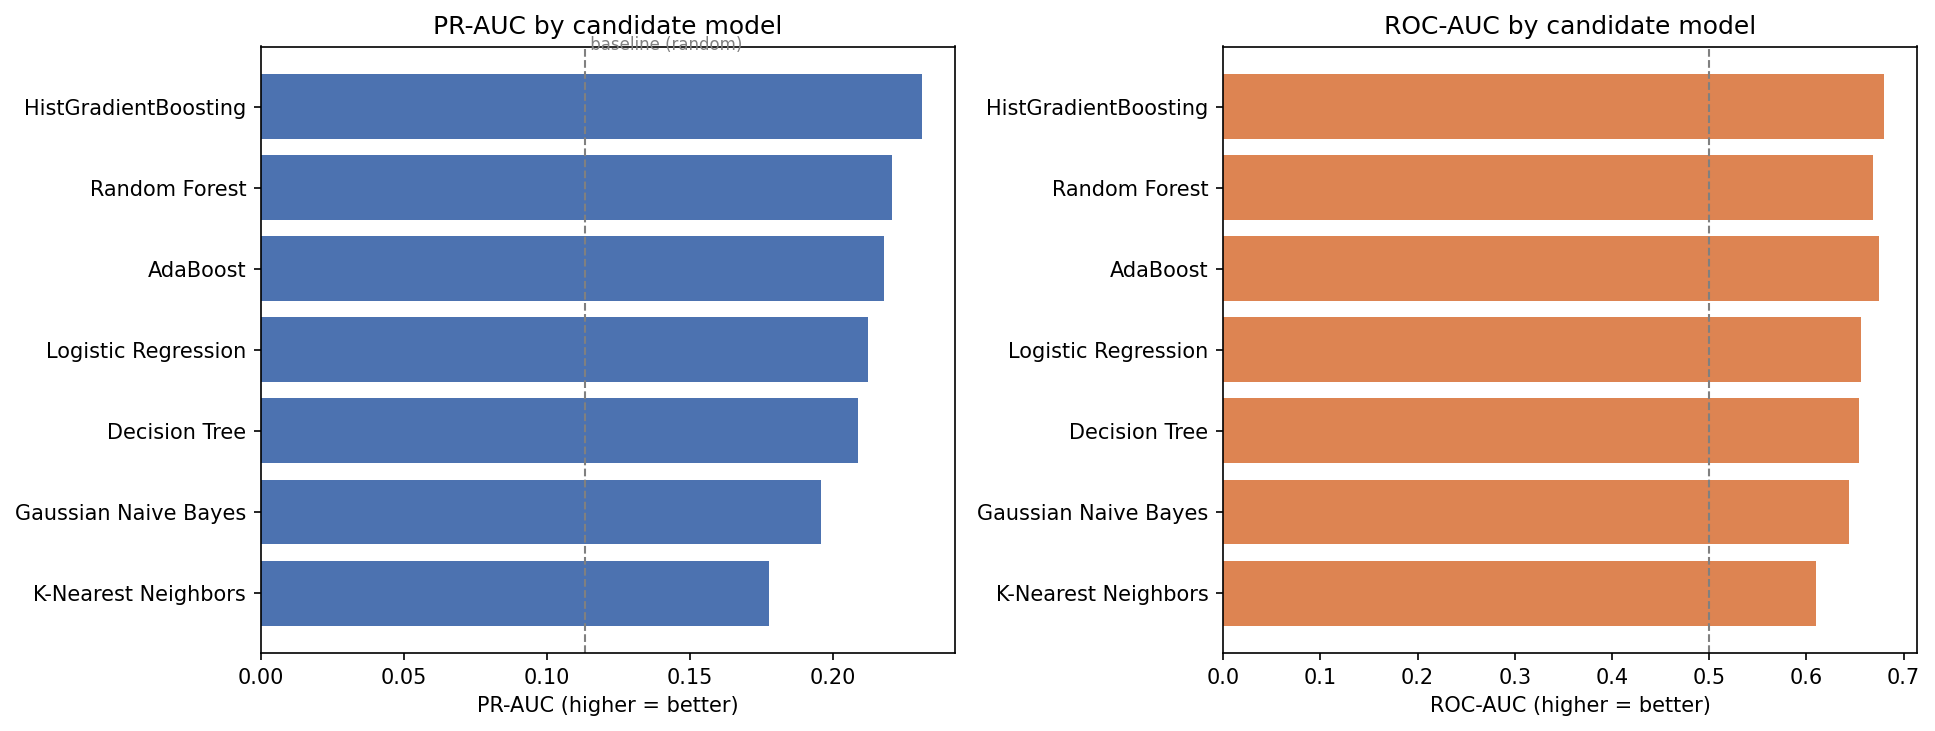

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
order = res_df["model"]
axes[0].barh(order, res_df["pr_auc"], color="#4C72B0")
axes[0].invert_yaxis()
axes[0].set_xlabel("PR-AUC (higher = better)")
axes[0].set_title("PR-AUC by candidate model")
axes[0].axvline(y_test.mean(), color="gray", linestyle="--", linewidth=1)
axes[0].text(y_test.mean(), -0.7, " baseline (random)", color="gray", fontsize=8)

axes[1].barh(order, res_df["roc_auc"], color="#DD8452")
axes[1].invert_yaxis()
axes[1].set_xlabel("ROC-AUC (higher = better)")
axes[1].set_title("ROC-AUC by candidate model")
axes[1].axvline(0.5, color="gray", linestyle="--", linewidth=1)

plt.tight_layout()
plt.savefig("chart_metrics.png", dpi=150, bbox_inches="tight")
plt.show()


## 7. Diversity Analysis — เหตุผลเชิงลึกสำหรับการเลือก Base Learner ใน Stacking

ความแม่นยำเดี่ยวไม่ใช่เกณฑ์เดียวในการเลือก base learner สำหรับ stacking — **stacking ได้ประโยชน์จาก base learner ที่ทำนายผิดคนละแบบ** (diversity) เพราะ meta-learner จะเรียนรู้ที่จะรวมจุดแข็งของแต่ละตัวได้ ถ้า base learner สองตัวทำนายเหมือนกันหมด (correlation สูงมาก) การ stack แทบไม่ต่างจากใช้ตัวเดียว

เราวัด diversity ด้วย **correlation ของ predicted probability** บน test set ระหว่างแต่ละคู่โมเดล

In [ ]:
proba_df = pd.DataFrame(proba_store)
corr = proba_df.corr()
print(corr.round(3).to_string())


                      Logistic Regression  K-Nearest Neighbors  Gaussian Naive Bayes  Decision Tree  Random Forest  AdaBoost  HistGradientBoosting
Logistic Regression                 1.000                0.581                 0.664          0.668          0.904     0.878                 0.844
K-Nearest Neighbors                 0.581                1.000                 0.451          0.429          0.559     0.563                 0.541
Gaussian Naive Bayes                0.664                0.451                 1.000          0.434          0.612     0.647                 0.560
Decision Tree                       0.668                0.429                 0.434          1.000          0.756     0.741                 0.785
Random Forest                       0.904                0.559                 0.612          0.756          1.000     0.912                 0.923
AdaBoost                            0.878                0.563                 0.647          0.741          0.912    

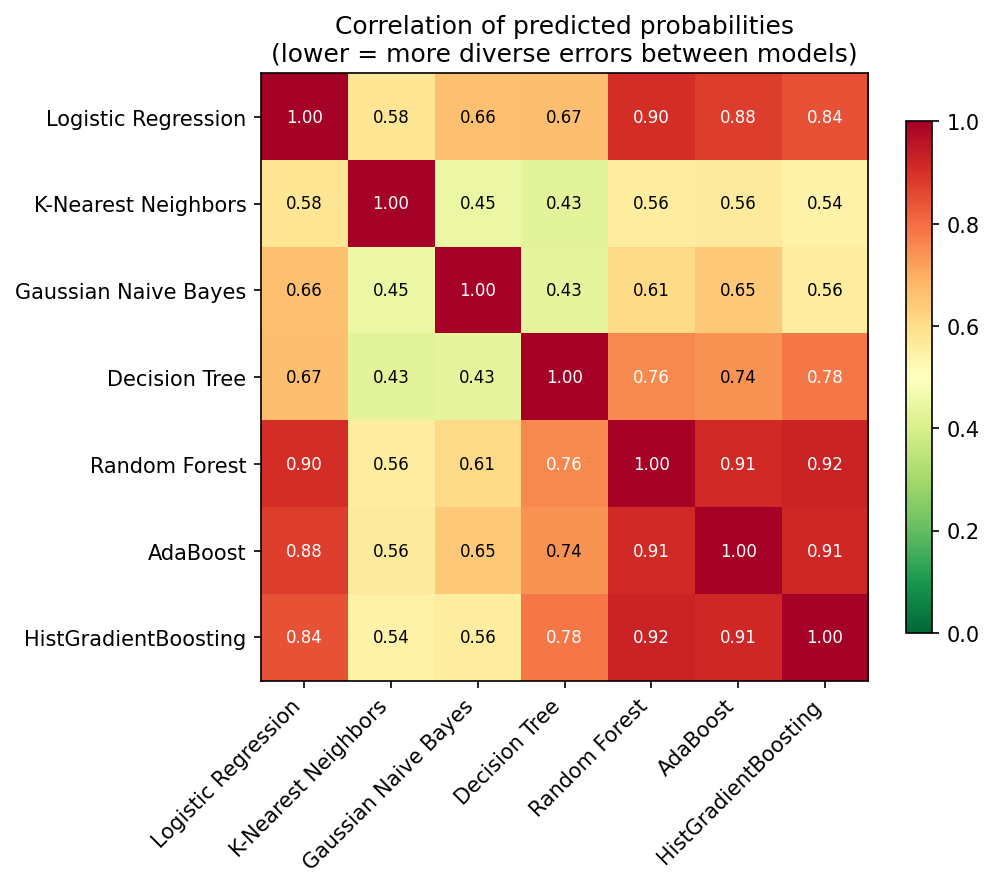

In [ ]:
fig2, ax2 = plt.subplots(figsize=(7, 6))
im = ax2.imshow(corr.values, cmap="RdYlGn_r", vmin=0, vmax=1)
ax2.set_xticks(range(len(corr.columns)))
ax2.set_yticks(range(len(corr.columns)))
ax2.set_xticklabels(corr.columns, rotation=45, ha="right")
ax2.set_yticklabels(corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax2.text(j, i, f"{corr.values[i,j]:.2f}", ha="center", va="center",
                  color="white" if corr.values[i, j] > 0.75 else "black", fontsize=8)
ax2.set_title("Correlation of predicted probabilities\n(lower = more diverse errors between models)")
plt.colorbar(im, ax=ax2, shrink=0.8)
plt.tight_layout()
plt.savefig("chart_corr.png", dpi=150, bbox_inches="tight")
plt.show()


## 8. สรุปผลและเหตุผลในการเลือก Base Learner

### ผลเชิงตัวเลข (จากรันในสภาพแวดล้อมนี้ ซึ่งไม่มี XGBoost ติดตั้งไว้ — ดูหมายเหตุด้านล่าง)

1. **ตระกูล tree-based ชนะทุกตระกูลอื่นอย่างสม่ำเสมอ** ทั้ง PR-AUC และ ROC-AUC: HistGradientBoosting (0.231/0.680), Random Forest (0.221/0.669), AdaBoost (0.218/0.675) อยู่ 3 อันดับแรก ขณะที่ Logistic Regression, Decision Tree เดี่ยว, Naive Bayes, และ KNN ตามหลังทั้งหมด
   - สอดคล้องกับธรรมชาติของข้อมูล: feature ส่วนใหญ่ผ่าน **label encoding** (ไม่ใช่ one-hot) และมี **interaction term** ที่สร้างไว้เอง (เช่น `age_x_medications`, `hospital_stay_x_inpatient`) ซึ่งโมเดลเชิงเส้น/ระยะทาง (LR, KNN) ตีความความสัมพันธ์แบบไม่เป็นเชิงเส้นจากค่า label-encoded ได้ไม่ดีเท่าโมเดลที่แบ่ง threshold ทีละฟีเจอร์แบบต้นไม้
   - KNN แย่ที่สุด (ROC-AUC 0.610) เพราะ curse of dimensionality กับฟีเจอร์ ~54 มิติ ทำให้ระยะทางแบบ Euclidean สูญเสียความหมาย และ F2 ที่ threshold 0.5 เกือบเป็น 0 (0.006) เพราะ KNN ให้ predicted probability กระจุกตัวใกล้ base rate ไม่ค่อยดันสูงเกิน 0.5 เลย — เช่นเดียวกับ AdaBoost ที่ F2@0.5 ต่ำผิดปกติ (0.006) ทั้งที่ ROC-AUC สูง เพราะ AdaBoost ให้ probability ที่ไม่ calibrate (มักต่ำกว่า 0.5 เกือบหมด) นี่คือเหตุผลที่ทั้ง pipeline หลักและโน้ตบุ๊กนี้เน้นดูที่ PR-AUC/ROC-AUC (threshold-independent) มากกว่า metric ที่ threshold ตายตัว แล้วค่อยหา threshold ที่เหมาะสมทีหลัง (ตามที่ทำใน 07)

2. **Diversity**: กลุ่มโมเดลตระกูลต้นไม้ (RF, AdaBoost, HistGB) มี correlation ของ prediction สูงกันเอง (0.91–0.92) เพราะใช้กลไกแบ่ง threshold แบบเดียวกัน ในขณะที่ KNN และ Naive Bayes ให้ prediction ที่ต่างออกไปมากที่สุด (correlation ~0.43–0.58 กับตัวอื่น) แต่แลกมาด้วย accuracy ที่ต่ำกว่ามาก — จึง**ไม่คุ้ม**ที่จะเอาไป stack (diversity ที่มาจากโมเดลที่แม่นยำต่ำ มักทำให้ meta-learner เรียนรู้ได้ยากกว่าได้ประโยชน์)

3. **RF vs Boosting**: แม้ RF และ HistGradientBoosting มี correlation สูงถึง 0.923 (สูงสุดในกลุ่ม top-2) แต่ทั้งสองมาจาก**กลไกลดข้อผิดพลาดคนละแบบ**:
   - **Random Forest** = bagging → ลด **variance** ด้วยการเฉลี่ยต้นไม้อิสระจากกันที่ผ่าน bootstrap sampling + random feature subset
   - **Boosting (XGBoost/HistGB)** = sequential correction → ลด **bias** ด้วยการเรียนรู้แก้ residual error ของรอบก่อนหน้าทีละสเต็ป

   ความต่างเชิงกลไกนี้ (ไม่ใช่แค่ correlation ตัวเลข) คือเหตุผลหลักที่งานวิจัยด้าน ensemble learning มักแนะนำให้จับคู่ bagging + boosting ใน stacking เพราะทั้งสองมี error pattern ที่เกิดจากคนละสาเหตุ (variance vs bias) ทำให้ meta-learner (Logistic Regression) มีข้อมูลเพียงพอที่จะแยกแยะว่ากรณีไหนควรเชื่อโมเดลไหนมากกว่า

### ทำไมถึงเลือก Random Forest + XGBoost (ไม่ใช่ HistGradientBoosting หรือ AdaBoost)

- **XGBoost vs HistGradientBoosting**: ทั้งคู่เป็น gradient boosting และให้ผลใกล้เคียงกันมาก (ตามที่เห็นจาก HistGB ในการทดลองนี้) แต่ XGBoost มี ecosystem ที่ mature กว่าสำหรับงานที่ต้องทำ `RandomizedSearchCV` ละเอียด (`05_improved_pipeline4.ipynb`) และมี `scale_pos_weight` ที่ควบคุม imbalance ได้ตรงไปตรงมา — เป็นเหตุผลเชิงปฏิบัติมากกว่าเหตุผลว่าตัวหนึ่งดีกว่าอีกตัวโดยพื้นฐาน (ผลลัพธ์จากการทดลองนี้ชี้ว่าใกล้เคียงกันมาก ควรระบุไว้ในรายงานว่าเป็นทางเลือกที่สมเหตุสมผลทั้งคู่)
- **AdaBoost vs XGBoost**: จาก `04_model_training.ipynb` (ทดลองก่อนหน้า) AdaBoost ให้ PR-AUC ต่ำกว่า XGBoost และในการทดลองนี้ก็ให้ predicted probability ที่ไม่ calibrate เลย (F2@0.5 ≈ 0) ทำให้ต้องพึ่ง threshold tuning มากเป็นพิเศษ — จึงถูกตัดออกจาก final pipeline เพราะซ้ำซ้อนกับ XGBoost (ทั้งคู่เป็น boosting) โดยไม่ได้ diversity เพิ่มขึ้นคุ้มค่า
- **Logistic Regression เป็น meta-learner**: เพราะ input ของ meta-learner คือ prediction ของ base learner (+ passthrough features) ซึ่งมีมิติน้อยกว่าฟีเจอร์ดิบมาก โมเดลง่ายและมี variance ต่ำอย่าง Logistic Regression จึงเพียงพอและลดความเสี่ยง overfitting ของชั้น meta ได้ดีกว่าใช้โมเดลซับซ้อนซ้อนกันอีกชั้น

### หมายเหตุสำคัญเรื่อง XGBoost ในการรันนี้

สภาพแวดล้อมที่ใช้รันโน้ตบุ๊กนี้**ไม่มี XGBoost ติดตั้งไว้** (เช็คจาก `HAS_XGB` ในเซลล์ imports) โค้ดจึงข้าม XGBoost ไปโดยอัตโนมัติและใช้ HistGradientBoosting เป็นตัวแทนตระกูล gradient boosting แทน — **เมื่อรันโน้ตบุ๊กนี้ในสภาพแวดล้อมเดิมที่มี XGBoost อยู่แล้ว (เช่นเดียวกับที่ใช้รัน 04–07)** โค้ดจะเพิ่ม XGBoost เข้าไปในตารางเปรียบเทียบโดยอัตโนมัติโดยไม่ต้องแก้อะไรเพิ่ม แนะนำให้รันซ้ำอีกครั้งก่อนใส่ตัวเลขลงสไลด์/รายงานฉบับสมบูรณ์ เพื่อให้มีตัวเลข XGBoost จริงควบคู่กับ HistGradientBoosting